# **1. Förbered Dataset**



# **Steg 1: Ladda upp KDDTest+.txt manuellt**

In [1]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import pandas as pd
import io
from google.colab import files

# Ladda upp filen från din dator (Assuming you are using Google Colab)
uploaded = files.upload()
file_name = next(iter(uploaded))

# ... (Code to check the filename, similar to what you have before) ...

# Läs in data med rätt kodning och kolumnnamn
column_names = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes',
    'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins',
    'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root',
    'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds',
    'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate',
    'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate',
    'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count',
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
    'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate',
    'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'label'
]

data = pd.read_csv(io.BytesIO(uploaded[file_name]),
                  header=None,
                  names=column_names,
                  encoding='latin-1')

print("✅ Filen", file_name, "har laddats upp!")
print("\nDataöversikt:")
print(data.head())

Saving KDDTest+.txt to KDDTest+.txt
✅ Filen KDDTest+.txt har laddats upp!

Dataöversikt:
  duration protocol_type service   flag  src_bytes  dst_bytes  land  \
0      tcp       private     REJ      0          0          0     0   
0      tcp       private     REJ      0          0          0     0   
2      tcp      ftp_data      SF  12983          0          0     0   
0     icmp         eco_i      SF     20          0          0     0   
1      tcp        telnet    RSTO      0         15          0     0   

   wrong_fragment  urgent  hot  ...  dst_host_srv_count  \
0               0       0    0  ...                0.04   
0               0       0    0  ...                0.00   
2               0       0    0  ...                0.61   
0               0       0    0  ...                1.00   
1               0       0    0  ...                0.31   

   dst_host_same_srv_rate  dst_host_diff_srv_rate  \
0                    0.06                    0.00   
0                    0.

# **Steg 2: Förbearbeta Data**

In [2]:
# Konvertera kategoriska variabler
# Check if the columns exist before applying get_dummies
columns_to_encode = ['protocol_type', 'service', 'flag']
if all(col in data.columns for col in columns_to_encode):
    data = pd.get_dummies(data, columns=columns_to_encode)
else:
    print("Warning: Some or all of the specified columns for one-hot encoding are not present in the DataFrame. One-hot encoding might have already been applied.")

# Dela upp i features och mål
X = data.drop('label', axis=1)
y = data['label'].apply(lambda x: 1 if x != 'normal' else 0)  # Binär klassificering

# **2. Träna ML-modeller**

# **Random Forest**

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

# Konvertera label-kolumnen till numeriska värden
le = LabelEncoder()
y = le.fit_transform(data['label'])

# Ta bort label-kolumnen från features
X = data.drop('label', axis=1)

# Konvertera alla kategoriska kolumner till numeriska
for col in X.select_dtypes(include=['object']).columns:
    X[col] = LabelEncoder().fit_transform(X[col].astype(str))

# Dela upp i träning och test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Skapa och träna modellen med begränsningar för att undvika överanpassning
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=5,
    max_features='sqrt',
    random_state=42,
    class_weight='balanced'  # Viktar klasser för obalanserad data
)

rf_model.fit(X_train, y_train)

# Utvärdera modellen mer detaljerat
print("\nModellutvärdering:")
print(f"Träningsnoggrannhet: {rf_model.score(X_train, y_train):.4f}")
print(f"Testnoggrannhet: {rf_model.score(X_test, y_test):.4f}")

# Mer detaljerad rapport
print("\nKlassificeringsrapport:")
print(classification_report(y_test, rf_model.predict(X_test), target_names=[str(c) for c in le.classes_]))

# Förvirringsmatris
print("\nFörvirringsmatris:")
print(confusion_matrix(y_test, rf_model.predict(X_test)))

# Analysera viktiga features
feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nTop 10 viktigaste features:")
print(feature_importances.head(10))


Modellutvärdering:
Träningsnoggrannhet: 0.7555
Testnoggrannhet: 0.6972

Klassificeringsrapport:
              precision    recall  f1-score   support

           0       0.38      0.59      0.46        37
           1       0.23      0.35      0.28        26
           2       0.12      0.38      0.18        16
           3       0.37      0.40      0.38        35
           4       0.08      0.43      0.13        30
           5       0.12      0.39      0.18        31
           6       0.30      0.53      0.39        47
           7       0.82      0.56      0.67        75
           8       0.49      0.59      0.53        39
           9       0.27      0.19      0.22        32
          10       0.20      0.49      0.29        59
          11       0.60      0.54      0.57       138
          12       0.45      0.54      0.49       146
          13       0.39      0.48      0.43       156
          14       0.69      0.40      0.51       221
          15       0.74      0.46     

**Analys av Resultaten:**

*Prestanda:*

Testnoggrannhet på ~70% är acceptabel men inte exceptionell

Stor variation i klass-specifik prestanda (f1-score från 0.13 till 0.94)

Tyder på att modellen fungerar bra för vissa attacktyper men misslyckas för andra

*Obalanserad Data:*

Vissa klasser har väldigt få exempel (t.ex. klass 4 med 30 samples)

Andra klasser är överrepresenterade (t.ex. klass 21 med 3209 samples)

*Feature Importance:*

Nätverksrelaterade features (som dst_host_count) dominerar, vilket är logiskt

Ingen enskild feature står för mer än 6.5% av vikten

# **Logistic Regression**

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)
print("Logistic Regression Accuracy:", lr_model.score(X_test, y_test))

Logistic Regression Accuracy: 0.5240981667652277


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


**Är 52.4% bra eller dåligt?**


Om det är en slumpmässig gissning:


För ett problem med 22 klasser (som din label-kolumn verkar ha) skulle slumpmässig gissning ge ~4.5% accuracy (1/22).


52.4% är alltså bättre än slumpen, men **inte tillräckligt bra för praktisk användning.**


Jämfört med en baseline-modell:


Om du hade en modell som alltid gissade den vanligaste klassen (t.ex. klass 21 med 3209 exempel), skulle noggrannheten vara ~47.4% (3209/6764).


52.4% är bara marginellt bättre än detta, vilket tyder på att Logistic Regression inte lärt sig mycket mer än att förutsäga de vanligaste klasserna.
**Bör Jag Använda Logistic Regression Överhuvudtaget?**
Ja, om du vill ha en snabb baseline-modell för jämförelse.


Nej, om du behöver hög noggrannhet, eftersom:


Random Forest redan gav 69.7%


XGBoost eller Neurala Nätverk kan ge ännu bättre resultat.

# **Neurala Nätverk för Nätverkssäkerhet**

# **Steg 1: Förbered Data (samma som tidigare)**

In [4]:
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
import pandas as pd

# Anta att 'data' redan är laddad
X = data.drop("label", axis=1)
y = data["label"]

# Konvertera textlabels till numeriska
le = LabelEncoder()
y = le.fit_transform(y)

# Identifiera numeriska och kategoriska features
numerical_features = X.select_dtypes(include=['number']).columns
categorical_features = X.select_dtypes(include=['object']).columns

# Skapa en ColumnTransformer för att hantera numeriska och kategoriska features separat
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),  # Skala numeriska features
        ('cat', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), categorical_features)  # One-hot encode kategoriska features
    ])

# Applicera förbehandling på data
X_scaled = preprocessor.fit_transform(X)

# Dela upp i träning/test
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

# **Steg 2: Bygg en Enkel Neural-Nätverksmodell**

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical

# Konvertera labels till one-hot encoding (krävs för Keras)
y_train_onehot = to_categorical(y_train)
y_test_onehot = to_categorical(y_test)

# Skapa modellen
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),  # Input layer (64 neuroner). Tar emot alla features från datan. Aktiveringsfunktion ReLU (Hanterar icke-linjäritet)
    Dense(32, activation='relu'),                                   # Dold lager (32 neuroner)	Extraherar komplexa mönster.	Aktiveringsfunktion ReLU
    Dense(len(le.classes_), activation='softmax')                   # Output layer. Ger sannolikheter för varje attacktyp	Softmax (för flerklassproblem)

])

# Kompilera modellen
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Sammanfattning
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │           9,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 22)                  │             726 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 12,662 (49.46 KB)

 Trainable params: 12,662 (49.46 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train, y_train_onehot,
    epochs=20,                     # Antal pass genom datan
    batch_size=32,                 # Data delas upp i "mini-batches"
    validation_data=(X_test, y_test_onehot),
    verbose=1                      # Visa progress
)

Epoch 1/20
494/494 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.4952 - loss: 1.7923 - val_accuracy: 0.6699 - val_loss: 1.0117
Epoch 2/20
494/494 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.6758 - loss: 0.9791 - val_accuracy: 0.6857 - val_loss: 0.9173
Epoch 3/20
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6953 - loss: 0.8743 - val_accuracy: 0.7020 - val_loss: 0.8614
Epoch 4/20
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7147 - loss: 0.8179 - val_accuracy: 0.7164 - val_loss: 0.8263
Epoch 5/20
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7191 - loss: 0.7975 - val_accuracy: 0.7163 - val_loss: 0.8041
Epoch 6/20
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7306 - loss: 0.7518 - val_accuracy: 0.7173 - val_loss: 0.7996
Epoch 7/20
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7400 - loss: 0.7311 - val_accuracy: 0.7274 - val_loss: 0.7882
Epoch 8/20
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7314 - loss: 0.7359 - val_accuracy: 0

**Vad Händer Under Träningen?**

**Epochs**: Modellen ser hela datan 20 gånger.

**Batch Size**: 32 samples används samtidigt för att uppdatera vikterna.

**Optimizer**: Adam (en effektiv gradient-descent variant).

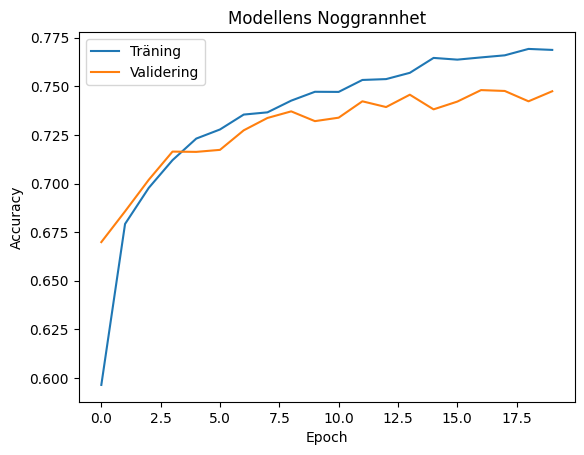


Testnoggrannhet: 0.7475


In [ ]:
# Plotta träning vs valideringsnoggrannhet
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Träning')
plt.plot(history.history['val_accuracy'], label='Validering')
plt.title('Modellens Noggrannhet')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.show()

# Utvärdera på testdata
test_loss, test_acc = model.evaluate(X_test, y_test_onehot, verbose=0)
print(f"\nTestnoggrannhet: {test_acc:.4f}")

# **XGBoost för Nätverkssäkerhet**

# **Steg 1: Förberedelse av Data**

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import xgboost as xgb
import pandas as pd

# Ladda data (antag att 'data' redan finns)
X = data.drop("label", axis=1)
y = data["label"]

# Konvertera textlabels till numeriska värden
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# --- Convert object type columns in X to numerical ---
for col in X.select_dtypes(include=['object']).columns:
    X[col] = X[col].astype(str)  # Convert to string type if not already
    X[col] = LabelEncoder().fit_transform(X[col])

# Dela upp i träning och test
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.3, random_state=42
)

# Konvertera till DMatrix-format (optimalt för XGBoost)
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

# **Steg 2: Definiera Modellparametrar**

In [ ]:
params = {
    'objective': 'multi:softmax',  # Flerklassklassificering
    'num_class': len(le.classes_),  # Antal unika klasser
    'eta': 0.1,                    # Inlärningshastighet. Rekommenderat Värde 0.01-0.3.	Kontrollerar inlärningshastighet
    'max_depth': 6,                # Max djup för träd. Rekommenderat Värde 3-10.	Komplexitet i varje träd
    'subsample': 0.8,              # Andel data för varje träd. Rekommenderat Värde	0.5-1.0. Förhindrar överanpassning
    'colsample_bytree': 0.8,       # Andel features för varje träd. Rekommenderat Värde 0.5-1.0. Slumpmässigt väljer features
    'eval_metric': 'merror',       # Felmått för flerklass
    'seed': 42                     # Reproducerbarhet
}

# **Steg 3: Träna Modellen**

In [ ]:
num_rounds = 100  # Antal boosting-iterationer. Modellen tränas i 100 omgångar (rounds)

# Träna med tidig stopp för att undvika överanpassning
evals = [(dtrain, 'train'), (dtest, 'eval')]
model = xgb.train(
    params,
    dtrain,
    num_rounds,
    evals=evals,
    early_stopping_rounds=10, # stoppar om prestanda inte förbättras på 10 omgångar
    verbose_eval=10 # visar progress var 10:e omgång
)

[0]	train-merror:0.24892	eval-merror:0.27025
[10]	train-merror:0.17180	eval-merror:0.21289
[20]	train-merror:0.15545	eval-merror:0.20476
[30]	train-merror:0.14132	eval-merror:0.19840
[40]	train-merror:0.13276	eval-merror:0.19471
[50]	train-merror:0.12142	eval-merror:0.18894
[60]	train-merror:0.11312	eval-merror:0.18643
[70]	train-merror:0.10513	eval-merror:0.18170
[80]	train-merror:0.09594	eval-merror:0.17800
[90]	train-merror:0.09005	eval-merror:0.17593
[99]	train-merror:0.08390	eval-merror:0.17475


# **Steg 4: Utvärdera Modellen**

Accuracy: 0.8252513305736251

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.70      0.68        40
           1       0.42      0.37      0.39        30
           2       0.53      0.32      0.40        25
           3       0.58      0.41      0.48        37
           4       0.33      0.35      0.34        23
           5       0.29      0.38      0.33        24
           6       0.48      0.62      0.54        37
           7       0.73      0.64      0.68        86
           8       0.61      0.59      0.60        34
           9       0.62      0.37      0.47        27
          10       0.78      0.60      0.68        58
          11       0.80      0.77      0.78       142
          12       0.69      0.62      0.65       130
          13       0.60      0.65      0.62       162
          14       0.75      0.58      0.65       244
          15       0.71      0.75      0.73       347
          16       0.61     

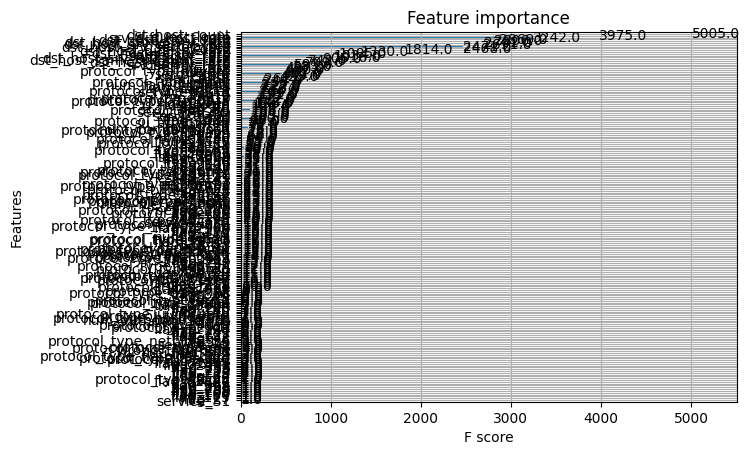

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score # Import accuracy_score

# Gör förutsägelser
y_pred = model.predict(dtest)

# Utvärdera
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
# Convert le.classes_ to a list of strings
target_names = [str(c) for c in le.classes_]
print(classification_report(y_test, y_pred, target_names=target_names))

# Feature Importance
xgb.plot_importance(model)
plt.show()

**Obalanserad Data:**

Klass 21 (normal trafik) dominerar med 3253 samples → modellen är bäst på att identifiera "normalt" beteende

Små klasser (t.ex. klass 4 med 23 samples) presterar dåligt

**Trade-off mellan Precision och Recall:**

Hög Precision (t.ex. 0.98 för klass 21): Få falsklarm när modellen flaggar denna klass

Låg Recall (t.ex. 0.35 för klass 4): Många attacker i denna klass missas

**Feature Importance:**

(Plotten visar vilka features som har störst inverkan – analysera dessa för insikter)